# La escalera de LGD: MCO, logit fraccional, beta, en dos etapas, árboles potenciados y Tobit

**Pregunta:** ¿Cuál de seis formas de modelo para la pérdida dado el incumplimiento de préstamos a pequeñas empresas ordena y calibra mejor fuera de muestra temporal, y qué muestra la brecha de calibración que el R cuadrado oculta?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (la LGD de recuperación y el indicador sustituto de C08)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- escribir la especificación de cada peldaño de la escalera de C08 (MCO, logit fraccional, beta, en dos etapas, árboles potenciados por gradiente, Tobit) y decir qué significa su predicción;
- reconstruir un peldaño ajustado a partir de los coeficientes versionados en el artefacto y predecir con `predict_lgd` del motor, de modo que un modelo versionado se pueda reutilizar y comprobar;
- reajustar los cinco peldaños del motor con `fit_ols`, `fit_fractional_logit`, `fit_beta`, `fit_hurdle` y `fit_tobit` sobre una muestra de verdad conocida, y leer qué recupera cada uno;
- explicar por qué el peldaño beta depende de un ajuste de extremos, y leer la sensibilidad versionada a él;
- comparar los peldaños fuera de tiempo en las seis cohortes de incumplimiento de C08, por R cuadrado, correlación de rangos y brecha de calibración, y decir qué muestra la brecha de calibración que no muestra el R cuadrado.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir sus versiones, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import lgd_models as lm

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Siete artefactos versionados del caso C08, la pérdida dado el incumplimiento de préstamos a pequeñas empresas. Uno es el artefacto de modelos `models-dc-2007-08.json`, que guarda la escalera ajustada (los coeficientes, la estandarización, los parámetros). Los otros seis son las variantes `dc-2003-06.json` a `dc-2020-23.json`, una por cohorte de incumplimiento, que guardan los resultados fuera de tiempo de cada peldaño: R cuadrado, correlación de rangos, la brecha de calibración, la calibración por tramo y las filas de pruebas del motor.

El diseño sigue las reglas de fuga de la investigación. La escalera se ajusta una vez, sobre los incumplimientos cuyo castigo cerró estrictamente antes del corte del 31 de diciembre de 2006, y cada cohorte desde 2007 es una prueba que el ajuste nunca vio. El objetivo es el indicador sustituto de castigos del notebook 01, así que todo lo que sigue es una afirmación sobre el indicador sustituto y no sobre una LGD de recuperación. Los artefactos fueron horneados con un motor anterior al instalado, y la celda siguiente imprime ambas versiones.

In [2]:
# Abrir el artefacto del modelo y las seis variantes por cohorte, y listar los peldaños con su biblioteca
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C08"
models = json.loads((DERIVED / "models-dc-2007-08.json").read_text(encoding="utf-8"))
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((DERIVED / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
fit = models["fit"]
print("artefacto del modelo horneado con riskvalidation:", models["provenance"]["riskvalidation_version"])
print("instalado:", rv.__version__)
print("corte de entrenamiento:", fit["training"]["cutoff_date"], "|", f"{fit['training']['n_defaults']:,}")
for rung in fit["ladder"]:
    print(f"{rung['rung_id'][:2]} {rung['library']} {rung['library_version']} | covariables {len(rung['covariates'])}")

artefacto del modelo horneado con riskvalidation: 1.0.1
instalado: 1.0.1
corte de entrenamiento: 2006-12-31 | 48,833
L1 riskvalidation 1.0.1 | covariables 16
L2 riskvalidation 1.0.1 | covariables 16
L3 riskvalidation 1.0.1 | covariables 16
L4 riskvalidation 1.0.1 | covariables 16
L5 catboost 1.2.10 | covariables 16
L6 riskvalidation 1.0.1 | covariables 16


## Método

### Paso 1: los seis peldaños y qué predice cada uno

Los seis peldaños predicen la LGD media de un préstamo dadas sus covariables $x$ (el logaritmo del monto y del plazo, las partes garantizada y de madurez, una marca de línea rotativa y las variables indicadoras de sector), con una columna de intercepto. El módulo `lgd_models` del motor implementa cinco de ellos en NumPy y SciPy puros; el sexto es el retador de árboles potenciados por gradiente del flujo de procesamiento.

| Peldaño | Especificación | Predicción |
|---|---|---|
| L1 MCO | $y = x'\beta + \varepsilon$ | $\hat y = \min(\max(x'\beta, 0), 1)$, recortada solo al predecir |
| L2 logit fraccional | $E[y \mid x] = 1 / (1 + e^{-x'\beta})$, cuasi-verosimilitud de Bernoulli (Papke y Wooldridge 1996) | $\hat y = 1 / (1 + e^{-x'\beta})$ |
| L3 beta | $y \sim \mathrm{Beta}(\mu\varphi, (1-\mu)\varphi)$, $\mu = 1 / (1 + e^{-x'\beta})$, $\mathrm{Var}(y) = \mu(1-\mu)/(1+\varphi)$ (Ferrari y Cribari-Neto 2004), ajustada sobre $\min(\max(y, \epsilon), 1-\epsilon)$ | $\hat y = \mu$ |
| L4 en dos etapas | etapa 1: $P(y>0 \mid x) = 1/(1+e^{-x'\gamma})$; etapa 2: $E[y \mid y>0, x] = 1/(1+e^{-x'\delta})$ entre los préstamos con $y > 0$ (Leow y Mues 2012; Tong, Mues y Thomas 2013) | $\hat y = P(y>0 \mid x)\,E[y \mid y>0, x]$ |
| L5 árboles potenciados por gradiente | CatBoost con la pérdida de entropía cruzada, 200 árboles de profundidad 6 | la salida del modelo, en [0, 1] |
| L6 Tobit | $y = \min(1, \max(0, y^*))$, $y^* = x'\beta + \varepsilon$, $\varepsilon \sim N(0, \sigma^2)$ (Tobin 1958) | $E[y \mid x]$ de la normal censurada, en forma cerrada |

(Fuentes: los docstrings de `riskvalidation.lgd_ead.lgd_models` en la versión 0.8.1, que nombran a los autores de arriba; los parámetros del árboles potenciados por gradiente los imprime la celda de datos.) Dos propiedades importan para lo que sigue. MCO puede predecir fuera de [0, 1], así que su predicción se recorta, lo que es una decisión del motor. El peldaño beta no puede tomar exactamente los valores 0 y 1, así que necesita el ajuste de extremos $\epsilon$ del paso 4. La celda de datos de arriba los lista con su biblioteca.

### Paso 2: los coeficientes versionados

Un peldaño lineal son sus coeficientes más la estandarización de sus cuatro covariables continuas (cada una se centra y escala con la media y la desviación estándar del tramo de entrenamiento, para que los coeficientes sean comparables). El artefacto guarda ambas cosas. MCO vive en la escala de la LGD y el logit fraccional y el Tobit en su propio enlace, así que sus números brutos no se pueden poner lado a lado; la celda divide las pendientes de cada peldaño por su mayor pendiente absoluta y las dibuja, lo que compara signo y peso relativo. Un coeficiente sobre una covariable estandarizada es el cambio del predictor lineal por desviación estándar; el indicador de línea rotativa y las variables de sector entran como 0 o 1.

estandarización de log_amount       media  11.3042  desviación estándar  1.1594
estandarización de log_term         media   3.8940  desviación estándar  0.9383
estandarización de guaranteed_share media   0.7518  desviación estándar  0.1358
estandarización de seasoning_share  media   0.8478  desviación estándar  0.4847
incumplimientos ajustados: 47,726


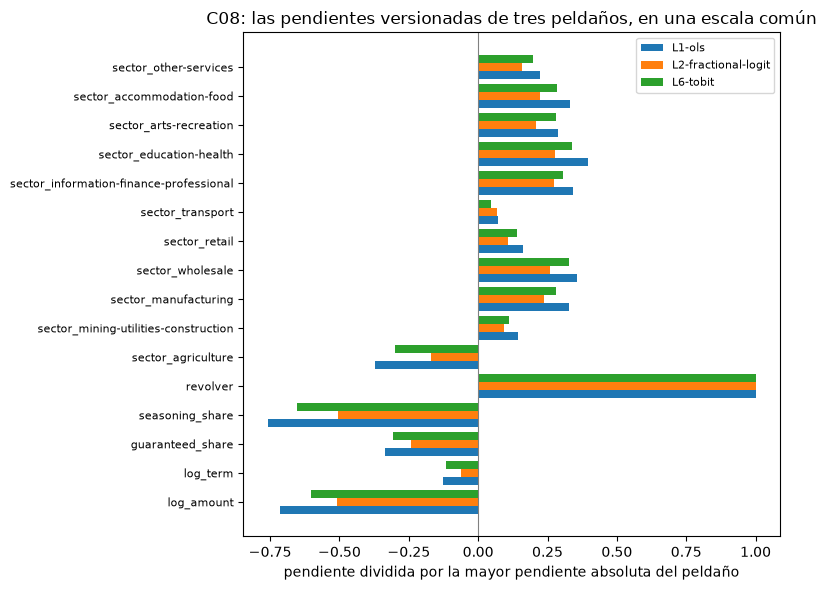

In [3]:
# Dibujar las pendientes de tres peldaños versionados, cada una escalada por su mayor pendiente absoluta
ladder = {r["rung_id"]: r for r in fit["ladder"]}
detail = {m["id"]: m["details"] for m in models["model"]}
coefs = {rid: np.array([c["estimate"] for c in r["coefficients"]]) for rid, r in ladder.items() if r["coefficients"]}
terms = [c["name"] for c in ladder["L1-ols"]["coefficients"]][1:]
standard = detail["L2-fractional-logit"]["standardisation"]
for name, s in standard.items():
    print(f"estandarización de {name:16s} media {s['mean']:8.4f}  desviación estándar {s['std']:7.4f}")
print("incumplimientos ajustados:", f"{detail['L2-fractional-logit']['n_fitted']:,}")

fig, ax = plt.subplots(figsize=(8, 6))
rows = np.arange(len(terms))
for k, rid in enumerate(("L1-ols", "L2-fractional-logit", "L6-tobit")):
    scaled = coefs[rid][1:] / np.abs(coefs[rid][1:]).max()
    ax.barh(rows + (k - 1) * 0.27, scaled, height=0.27, label=rid)
ax.set_yticks(rows)
ax.set_yticklabels(terms, fontsize=8)
ax.axvline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("pendiente dividida por la mayor pendiente absoluta del peldaño")
ax.set_title("C08: las pendientes versionadas de tres peldaños, en una escala común")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Los tres peldaños coinciden en la dirección casi en todas partes: el logaritmo del monto, la proporción garantizada y la proporción de antigüedad empujan la pérdida esperada a la baja, el indicador de línea rotativa la empuja al alza, y las variables de sector se mueven igual en MCO, logit fraccional y Tobit. Lo que cambia entre peldaños es el peso relativo, no la historia, y por eso las métricas de orden del paso 6 se parecen entre sí mientras los niveles no. La figura compara solo pendientes; todavía no dice nada sobre qué tan bien predice cada peldaño, lo que exige las cohortes que el ajuste nunca vio.

### Paso 3: predecir con el motor desde los coeficientes versionados

`LgdFit` del motor guarda exactamente lo que guarda el artefacto, así que un peldaño versionado puede reconstruirse y usarse: `LgdFit(kind, names, coefficients, extras)`. Los extras son la precisión beta $\varphi$ y el extremo $\epsilon$, los dos vectores de coeficientes de la etapa doble, y el $\sigma$ del Tobit. `predict_lgd(fit, X)` devuelve entonces la predicción, con solo la de MCO recortada.

La primera celda construye la matriz de diseño de tres préstamos inventados (una línea rotativa pequeña de comercio minorista, un préstamo mediano de manufactura, un préstamo grande de largo plazo agrícola) aplicando la estandarización versionada. Los valores de las covariables están inventados para ilustrar la aritmética; no son préstamos del archivo.

In [4]:
# Construir la matriz de diseño de tres préstamos inventados con la estandarización versionada
covariates = ladder["L2-fractional-logit"]["covariates"]
invented = [  # amount, term in months, guaranteed share, seasoning share, revolver, sector
    (50_000, 24, 0.50, 0.30, 1, "retail"),
    (350_000, 84, 0.75, 1.00, 0, "manufacturing"),
    (1_500_000, 240, 0.75, 1.00, 0, "agriculture"),
]
rows = []
for amount, term, guaranteed, seasoning, revolver, sector in invented:
    raw = {"log_amount": np.log(amount), "log_term": np.log(term)}
    raw.update(guaranteed_share=guaranteed, seasoning_share=seasoning)
    row = [1.0]
    for name in covariates:
        if name in raw:
            row.append((raw[name] - standard[name]["mean"]) / standard[name]["std"])
        elif name == "revolver":
            row.append(float(revolver))
        else:
            row.append(1.0 if name == f"sector_{sector}" else 0.0)
    rows.append(row)
X = np.array(rows)
print("matriz de diseño:", X.shape, "| primera fila:", np.round(X[0], 3))

matriz de diseño: (3, 17) | primera fila: [ 1.    -0.418 -0.763 -1.854 -1.13   1.     0.     0.     0.     0.
  1.     0.     0.     0.     0.     0.     0.   ]


La segunda celda reconstruye cinco peldaños como objetos `LgdFit` con los números versionados y predice los tres préstamos, seguidos de las dos etapas del peldaño de dos etapas.

In [5]:
# Reconstruir cinco peldaños versionados como LgdFit, predecir tres préstamos y abrir las dos etapas de uno
names = ("const", *covariates)
two = detail["L4-hurdle"]
stage1_coef = np.array(two["stage1_coefficients"])
extras_beta = {"phi": detail["L3-beta"]["phi"], "epsilon": ladder["L3-beta"]["epsilon"]}
extras_two = {"stage1_coefficients": stage1_coef, "severity_columns": tuple(two["severity_columns"])}
rebuilt = {
    "L1 OLS": lm.LgdFit("ols", names, coefs["L1-ols"]),
    "L2 logit fraccional": lm.LgdFit("fractional-logit", names, coefs["L2-fractional-logit"]),
    "L3 beta": lm.LgdFit("beta", names, coefs["L3-beta"], extras_beta),
    "L4 dos etapas": lm.LgdFit("hurdle", names, coefs["L4-hurdle"], extras_two),
    "L6 Tobit": lm.LgdFit("tobit", names, coefs["L6-tobit"], {"sigma": detail["L6-tobit"]["sigma"]}),
}
print(f"{'':36s} " + " ".join(f"préstamo {k}".rjust(11) for k in (1, 2, 3)))
for label, f in rebuilt.items():
    print(f"{label:36s} " + " ".join(f"{p:11.4f}" for p in lm.predict_lgd(f, X)))
stage1 = 1 / (1 + np.exp(-(X @ stage1_coef)))
stage2 = 1 / (1 + np.exp(-(X @ coefs["L4-hurdle"])))
print(f"{'etapa 1: P(y > 0)':36s} " + " ".join(f"{p:11.4f}" for p in stage1))
print(f"{'etapa 2: E[y | y > 0]':36s} " + " ".join(f"{p:11.4f}" for p in stage2))
print(f"{'etapa 1 por etapa 2':36s} " + " ".join(f"{p:11.4f}" for p in stage1 * stage2))

                                      préstamo 1  préstamo 2  préstamo 3
L1 OLS                                    0.9467      0.5396      0.3590
L2 logit fraccional                       0.9127      0.5328      0.3326
L3 beta                                   0.9057      0.5363      0.3424
L4 dos etapas                             0.9126      0.5332      0.3287
L6 Tobit                                  0.8972      0.5369      0.3596
etapa 1: P(y > 0)                         1.0000      0.9948      0.9768
etapa 2: E[y | y > 0]                     0.9127      0.5360      0.3365
etapa 1 por etapa 2                       0.9126      0.5332      0.3287


Los cinco peldaños coinciden en el orden de los tres préstamos, y difieren más en el primero, que está cerca del tope del rango. Ahí importa la elección del vínculo: MCO da 0.9467 y la esperanza del Tobit 0.8972, con las formas logísticas entre ambos. Las tres últimas filas reproducen a mano la predicción en dos etapas del motor desde sus dos etapas; la etapa 1 está casi en 1, es decir, cuando casi todo incumplimiento pierde algo la etapa "hay pérdida o no" aporta poca información y el modelo en dos etapas queda cerca del logit fraccional.

### Paso 4: el ajuste de extremos del peldaño beta

La densidad beta es cero o infinita en 0 y 1, así que el peldaño beta se ajusta sobre $y_\epsilon = \min(\max(y, \epsilon), 1-\epsilon)$, que calcula `endpoint_transform(y, epsilon)`. Qi y Zhao (2011), como registra el docstring del motor, encontraron que los resultados de la beta son muy sensibles a este número pequeño, y C08 informa la sensibilidad en vez de esconderla: `outputs.endpoint_sensitivity` guarda, para tres valores de $\epsilon$, la predicción media y el RMSE en la cohorte. La celda aplica la transformación a cinco valores e imprime la sensibilidad versionada, con los valores de $\varphi$ que el artefacto informa para los tres reajustes.

In [6]:
# Aplicar la transformación de extremos a cinco valores e imprimir la sensibilidad versionada a epsilon
sample = np.array([0.0, 0.2, 0.5, 0.97, 1.0])
for eps in (0.0001, 0.001, 0.01):
    print(f"epsilon={eps:<7}", lm.endpoint_transform(sample, eps))
print()
sens = cohort["2007-08"]["outputs"]["endpoint_sensitivity"]
print(f"{'epsilon':>8s} {'predicción media':>26s} {'RMSE':>8s}")
for row in sens:
    print(f"{row['epsilon']:8.4f} {row['mean_predicted']['value']:26.4f} {row['rmse']:8.4f}")
print("precisión beta phi del ajuste versionado (epsilon 0,001):", round(detail["L3-beta"]["phi"], 4))

epsilon=0.0001  [1.000e-04 2.000e-01 5.000e-01 9.700e-01 9.999e-01]
epsilon=0.001   [0.001 0.2   0.5   0.97  0.999]
epsilon=0.01    [0.01 0.2  0.5  0.97 0.99]

 epsilon           predicción media     RMSE
  0.0001                     0.7568   0.2928
  0.0010                     0.7503   0.2942
  0.0100                     0.7402   0.2970
precisión beta phi del ajuste versionado (epsilon 0,001): 2.7105


La predicción media del peldaño beta se mueve con $\epsilon$ mientras el RMSE casi no lo hace: quien elige $\epsilon$ por el mejor RMSE también elige un nivel. Un validador debe pedir la sensibilidad y la brecha de calibración en el valor elegido, que es lo que miran los pasos 6 y 7.

### Paso 5: reajustar los peldaños del motor sobre una muestra de verdad conocida

El artefacto versionado guarda los coeficientes ajustados pero no los 47.726 préstamos de entrenamiento (el archivo SBA es un conjunto de terceros que no se versiona), así que los ajustes no se pueden repetir aquí sobre los datos reales. Para ver trabajar las funciones `fit_*` del motor, la celda siguiente genera una muestra pequeña en el notebook, **un juguete con verdad conocida, no un caso**: 4.000 préstamos, dos covariables, un cuerpo de pérdidas con distribución beta, 18% de curas exactamente en 0 y 8% de pérdidas totales exactamente en 1. No se lee ningún archivo y no se escribe nada; la semilla es fija. Luego ajusta los cinco peldaños del motor sobre el mismo diseño e informa la predicción media, el RMSE contra el valor realizado y el R cuadrado.

Qué mirar: la media de la LGD realizada es el nivel objetivo, y un peldaño bien calibrado lo reproduce. MCO con intercepto y la cuasi-verosimilitud logística lo hacen por sus propias ecuaciones de estimación; los otros peldaños no tienen por qué, y el peldaño beta se ajusta sobre los valores con extremos corregidos.

In [7]:
# Generar una muestra de juguete con verdad conocida y ajustar los cinco peldaños del motor
rng = np.random.default_rng(20261021)
n = 4000
x1, x2 = rng.normal(size=n), rng.normal(size=n)
Xt = np.column_stack([np.ones(n), x1, x2])
mu = 1 / (1 + np.exp(-(0.4 + 0.8 * x1 - 0.5 * x2)))
body = rng.beta(mu * 4.0, (1 - mu) * 4.0)
y = np.where(rng.random(n) < 0.18, 0.0, np.where(rng.random(n) < 0.08 / 0.82, 1.0, body))
print(f"muestra de juguete: n={n} | proporción en 0={np.mean(y == 0):.3f} | proporción en 1={np.mean(y == 1):.3f}")
print(f"LGD realizada media={y.mean():.4f}")

toy = {
    "L1 OLS": lm.fit_ols(Xt, y),
    "L2 logit fraccional": lm.fit_fractional_logit(Xt, y),
    "L3 beta (epsilon 0.001)": lm.fit_beta(Xt, y, 0.001),
    "L4 dos etapas": lm.fit_hurdle(Xt, y),
    "L6 Tobit": lm.fit_tobit(Xt, y),
}
print(f"{'':34s} {'predicción media':>24s} {'RMSE':>8s} {'R cuad.':>10s}")
for label, f in toy.items():
    p = lm.predict_lgd(f, Xt)
    r2 = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
    print(f"{label:34s} {p.mean():24.4f} {np.sqrt(np.mean((y - p) ** 2)):8.4f} {r2:10.4f}")

muestra de juguete: n=4000 | proporción en 0=0.167 | proporción en 1=0.083
LGD realizada media=0.5217
                                           predicción media     RMSE    R cuad.
L1 OLS                                               0.5217   0.3272     0.1480
L2 logit fraccional                                  0.5217   0.3270     0.1486
L3 beta (epsilon 0.001)                              0.4881   0.3342     0.1109
L4 dos etapas                                        0.5219   0.3272     0.1479
L6 Tobit                                             0.5033   0.3291     0.1379


La tabla cuenta la historia del nivel en números; la celda siguiente la dibuja. Corta la muestra de juguete en diez grupos según la primera covariable y grafica, para cada peldaño, la predicción media del grupo contra la LGD realizada media del mismo grupo, de modo que un peldaño que acierta la pendiente pero no el nivel se vea como una línea paralela.

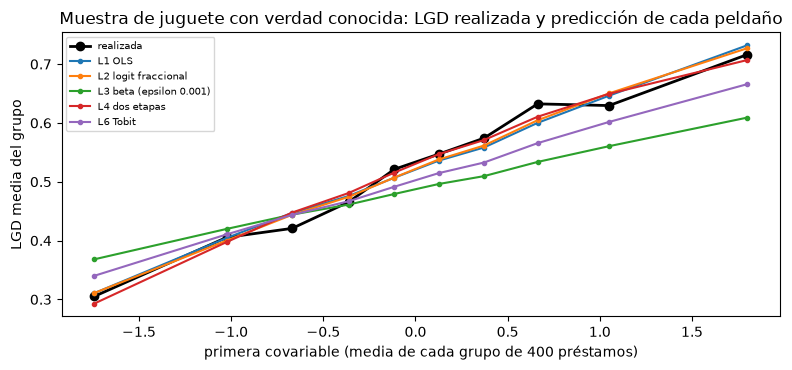

In [8]:
# Dibujar la predicción media de cada peldaño y la LGD realizada media en diez grupos de la primera covariable
groups = np.array_split(np.argsort(x1), 10)
centre = [x1[g].mean() for g in groups]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(centre, [y[g].mean() for g in groups], "k-o", linewidth=2, label="realizada")
for label, f in toy.items():
    pred = lm.predict_lgd(f, Xt)
    ax.plot(centre, [pred[g].mean() for g in groups], marker=".", label=label)
ax.set_xlabel("primera covariable (media de cada grupo de 400 préstamos)")
ax.set_ylabel("LGD media del grupo")
ax.set_title("Muestra de juguete con verdad conocida: LGD realizada y predicción de cada peldaño")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Las cinco curvas siguen a la curva realizada en la forma: suben con la covariable y se aplanan en los extremos, lo que las formas logísticas hacen por construcción y MCO hace dentro del recorte. El desfase vertical es donde difieren. MCO, el logit fraccional y el peldaño de dos etapas quedan sobre la línea realizada, el peldaño beta corre por debajo en todo el rango, y la esperanza del Tobit queda algo por debajo en el extremo alto. Ese desfase es el error de nivel de la tabla, visto ahora como función de la covariable: un peldaño puede ordenar bien los préstamos y aun así ponerlos todos demasiado bajos, que es el patrón que muestran más abajo las cohortes fuera de muestra temporal.

Ahora la sensibilidad del peldaño beta a $\epsilon$ sobre este juguete, reajustando tres veces, y la descomposición por curas de la investigación, $E[LGD] = P_{cura}\,LGD_{cura} + (1 - P_{cura})\,LGD_{liq}$, que calcula `cure_decomposition`. Es la descomposición de los practicantes; el motor marca su única fuente académica como NO VERIFICADA, así que el notebook enuncia la identidad y no cita a ningún autor. La celda usa la muestra de juguete y probabilidades inventadas.

In [9]:
# Reajustar el peldaño beta con tres valores de epsilon y aplicar la descomposición por curas a datos inventados
print(f"media realizada en el juguete: {y.mean():.4f}")
for eps in (0.0001, 0.001, 0.01):
    f = lm.fit_beta(Xt, y, eps)
    print(f"epsilon={eps:<7} predicción media {lm.predict_lgd(f, Xt).mean():.4f}  phi {f.extras['phi']:.4f}")
p_cure = np.array([0.30, 0.50])
cure = lm.cure_decomposition(p_cure, np.array([0.05, 0.10]), np.array([0.60, 0.70]))
print("descomposición por curas para P_cura 0,30 y 0,50 (LGD_cura 0,05 y 0,10, LGD_liq 0,60 y 0,70):", cure)

media realizada en el juguete: 0.5217
epsilon=0.0001  predicción media 0.4776  phi 0.6375
epsilon=0.001   predicción media 0.4881  phi 0.8141
epsilon=0.01    predicción media 0.5022  phi 1.1691
descomposición por curas para P_cura 0,30 y 0,50 (LGD_cura 0,05 y 0,10, LGD_liq 0,60 y 0,70): [0.435 0.4  ]


### Paso 6: fuera de muestra temporal, en las seis cohortes

De vuelta a la escalera real. Cada variante por cohorte guarda `outputs.rung_comparison`, los puntajes fuera de muestra temporal de cada peldaño en esa cohorte: R cuadrado, RMSE, MAE, correlación de rangos de Spearman y la brecha de calibración (el valor realizado medio del indicador menos la media predicha). La figura dibuja el R cuadrado y la brecha de calibración de cada peldaño por cohorte. Un peldaño que no pudo evaluarse en una cohorte no tiene punto ahí. La brecha de calibración es la cifra a la que apuntan la investigación y las pruebas del motor junto al R cuadrado, porque el R cuadrado es bajo para todo modelo de LGD (Loterman y otros 2012, según informa el docstring del motor, hallaron R cuadrado promedio entre 4% y 43%).

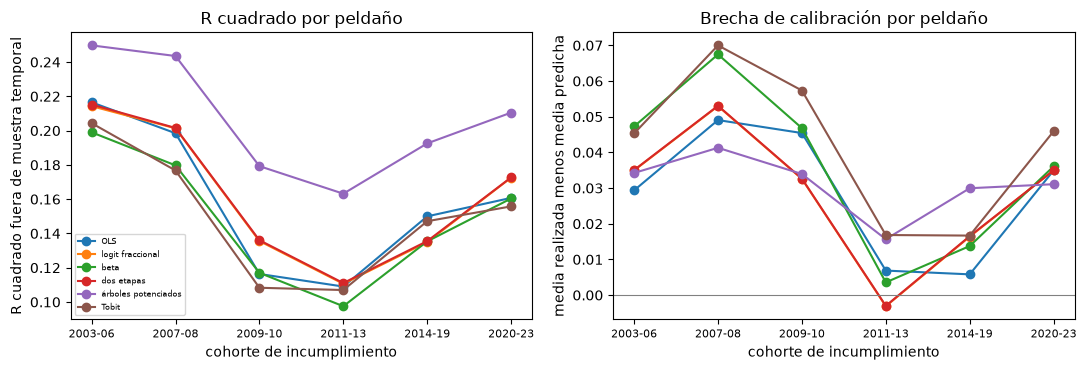

In [10]:
# Dibujar el R cuadrado y la brecha de calibración de cada peldaño en cada una de las seis cohortes
score = {c: {r["rung_id"]: r for r in cohort[c]["outputs"]["rung_comparison"]} for c in COHORTS}
short = {"L1-ols": "OLS", "L2-fractional-logit": "logit fraccional", "L3-beta": "beta",
         "L4-hurdle": "dos etapas", "L5-gradient-boosted": "árboles potenciados", "L6-tobit": "Tobit"}
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
for rung in ladder:
    where = [c for c in COHORTS if rung in score[c]]
    xs = [COHORTS.index(c) for c in where]
    left.plot(xs, [score[c][rung]["r2"] for c in where], marker="o", label=short[rung])
    right.plot(xs, [score[c][rung]["calibration_gap"] for c in where], marker="o", label=short[rung])
right.axhline(0.0, color="grey", linewidth=0.8)
for ax, ylabel in ((left, "R cuadrado fuera de muestra temporal"), (right, "media realizada menos media predicha")):
    ax.set_xticks(range(len(COHORTS)))
    ax.set_xticklabels(COHORTS, fontsize=8)
    ax.set_xlabel("cohorte de incumplimiento")
    ax.set_ylabel(ylabel)
left.set_title("R cuadrado por peldaño")
right.set_title("Brecha de calibración por peldaño")
left.legend(fontsize=6)
fig.tight_layout()
plt.show()

El panel izquierdo muestra el orden que da el R cuadrado: el peldaño de árboles potenciados está arriba en todas las cohortes, los cinco peldaños paramétricos se agrupan debajo, y todos los valores se mantienen bajos, entre cerca de 0,10 y 0,25. El panel derecho es el otro criterio. Casi todos los puntos están sobre cero, de modo que el indicador realizado supera a la predicción casi en todas partes, y el peldaño de árboles potenciados, el mejor a la izquierda, no es sistemáticamente el más cercano a cero a la derecha. La celda siguiente cuenta ambas afirmaciones.

In [11]:
# Contar las cohortes donde el mejor R cuadrado es también la menor brecha absoluta, y las brechas positivas
all_r2 = [r["r2"] for c in COHORTS for r in score[c].values()]
gaps = [r["calibration_gap"] for c in COHORTS for r in score[c].values()]
print(f"puntajes peldaño-cohorte: {len(all_r2)} | R cuadrado desde {min(all_r2):.4f} hasta {max(all_r2):.4f}")
print(f"brechas de calibración positivas (realizado sobre predicho): {sum(g > 0 for g in gaps)} de {len(gaps)}")
same = 0
for c in COHORTS:
    best_r2 = max(score[c], key=lambda k: score[c][k]["r2"])
    best_gap = min(score[c], key=lambda k: abs(score[c][k]["calibration_gap"]))
    same += best_r2 == best_gap
    print(f"{c}: mejor R cuadrado {short[best_r2]:18s} | menor brecha absoluta {short[best_gap]}")
print(f"cohortes donde coinciden: {same} de {len(COHORTS)}")
absent = [(c, rid) for c in COHORTS for rid in ladder if rid not in score[c]]
print("peldaños ausentes de la comparación de una cohorte:", [(c, short[r]) for c, r in absent])

puntajes peldaño-cohorte: 36 | R cuadrado desde 0.0975 hasta 0.2497
brechas de calibración positivas (realizado sobre predicho): 34 de 36
2003-06: mejor R cuadrado árboles potenciados | menor brecha absoluta OLS
2007-08: mejor R cuadrado árboles potenciados | menor brecha absoluta árboles potenciados
2009-10: mejor R cuadrado árboles potenciados | menor brecha absoluta logit fraccional
2011-13: mejor R cuadrado árboles potenciados | menor brecha absoluta dos etapas
2014-19: mejor R cuadrado árboles potenciados | menor brecha absoluta OLS
2020-23: mejor R cuadrado árboles potenciados | menor brecha absoluta árboles potenciados
cohortes donde coinciden: 2 de 6
peldaños ausentes de la comparación de una cohorte: []


### Paso 7: calibración por tramo y las pruebas del motor

La media puede ser correcta mientras la forma no lo es, así que cada cohorte guarda además `calibration_by_bucket`: los préstamos de la cohorte se cortan en cinco grupos iguales según la LGD predicha, y para cada grupo la media predicha y la media realizada. Un peldaño bien calibrado queda sobre la diagonal. La celda dibuja la cohorte 2007-08 para el peldaño de logit fraccional y el de árboles potenciados.

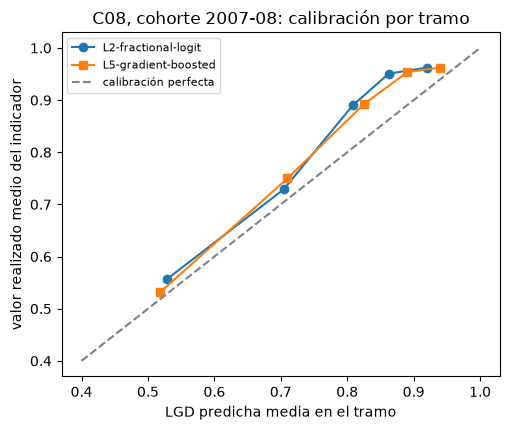

In [12]:
# Dibujar la calibración por tramo de dos peldaños en la cohorte 2007-08
o = cohort["2007-08"]["outputs"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for rung_id, marker in (("L2-fractional-logit", "o"), ("L5-gradient-boosted", "s")):
    buckets = [x for x in o["calibration_by_bucket"] if x["rung_id"] == rung_id]
    predicted = [x["predicted"]["value"] for x in buckets]
    realised = [x["realised"]["value"] for x in buckets]
    ax.plot(predicted, realised, marker=marker, label=rung_id)
ax.plot([0.4, 1.0], [0.4, 1.0], color="grey", linestyle="--", label="calibración perfecta")
ax.set_xlabel("LGD predicha media en el tramo")
ax.set_ylabel("valor realizado medio del indicador")
ax.set_title("C08, cohorte 2007-08: calibración por tramo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Ambas curvas quedan sobre la diagonal en todos los tramos: donde el peldaño predice 0,5 el valor realizado es mayor, y la distancia es máxima en los tramos centrales y no en los extremos. El peldaño de árboles potenciados queda más cerca de la diagonal que el logit fraccional, en línea con su menor brecha, y aun así no sobre ella. Esta es la forma detrás de una brecha media positiva: es un error de nivel en todo el rango de predicciones y no un artefacto de unos pocos préstamos extremos. Las pruebas propias del motor convierten la brecha en un semáforo, y la celda siguiente imprime sus filas versionadas.

In [13]:
# Imprimir las filas de pruebas del motor versionadas para la cohorte 2007-08 de dos peldaños
light = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}
print("horneado con riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
shown = ("L2-fractional-logit", "L5-gradient-boosted")
for t in cohort["2007-08"]["tests"]:
    if t["model_id"] in shown and t["test_id"] != "lgd_ead.downturn_coverage":
        p = "n/a" if t["p_value"] is None else f"{t['p_value']:.3g}"
        print(f"{t['test_id'][8:]:30s} {t['model_id']:21s} {light[t['light']]:8s} métrica {t['metric']:.4f}  p {p}")

horneado con riskvalidation: 1.0.1
lgd_calibration_by_segment     L2-fractional-logit   rojo     métrica 0.0530  p 2.78e-188
lgd_discrimination             L2-fractional-logit   verde    métrica 0.6301  p 0
lgd_calibration_over_time      L2-fractional-logit   rojo     métrica 0.0748  p 8.61e-147
lgd_calibration_by_segment     L5-gradient-boosted   rojo     métrica 0.0413  p 8.58e-121
lgd_discrimination             L5-gradient-boosted   verde    métrica 0.6762  p 0
lgd_calibration_over_time      L5-gradient-boosted   rojo     métrica 0.0947  p 6.23e-219


## Resultados

**Respuesta:** Fuera de muestra temporal, en las seis cohortes de incumplimiento de C08, el peldaño de árboles potenciados tiene el mayor R cuadrado en las seis, pero todo R cuadrado queda entre 0,0975 y 0,2497, el peldaño con la menor brecha de calibración es el de mayor R cuadrado en solo 2 de las 6 cohortes, y en 34 de los 36 puntajes peldaño-cohorte el indicador realizado está sobre la predicción. En una muestra de juguete cuya media es 0,5217, MCO, el logit fraccional y el peldaño de dos etapas la reproducen (0,5217, 0,5217 y 0,5219) con R cuadrado entre 0,1479 y 0,1486, mientras el peldaño beta da 0,4881: lo que separa a los peldaños es el nivel, no el R cuadrado.

- **Un peldaño versionado es un modelo que se puede correr.** Solo con los coeficientes y la estandarización versionados, `LgdFit` y `predict_lgd` dan la LGD del logit fraccional para los tres préstamos inventados: 0,9127, 0,5328 y 0,3326. Las dos etapas del peldaño de dos etapas se multiplican de vuelta hasta su propia predicción (0,9126, 0,5332 y 0,3287), con la etapa 1 en 1,0000, 0,9948 y 0,9768.
- **El peldaño beta depende del ajuste de extremos.** En la cohorte versionada 2007-08 su predicción media es 0,7568, 0,7503 y 0,7402 para $\epsilon$ igual a 0,0001, 0,001 y 0,01, mientras el RMSE pasa de 0,2928 a 0,2970. En el juguete los mismos tres valores dan 0,4776, 0,4881 y 0,5022 frente a una media realizada de 0,5217.
- **Fuera de muestra temporal, el mejor R cuadrado no siempre es la mejor calibración.** El peldaño de árboles potenciados tiene el mayor R cuadrado en las seis cohortes y la menor brecha absoluta en 2 de ellas (2007-08 y 2020-23); la menor brecha es de MCO en 2003-06 y 2014-19, del logit fraccional en 2009-10 y del peldaño de dos etapas en 2011-13. Los seis peldaños se evaluaron en las seis cohortes.
- **Las pruebas del motor convierten la brecha en un semáforo.** En 2007-08 el logit fraccional (brecha 0,0530) y el peldaño de árboles potenciados (0,0413) están en rojo en calibración y en verde en discriminación (Spearman 0,6301 y 0,6762): el orden funciona y el nivel es demasiado bajo, para un indicador cuya dirección de sesgo declara el artefacto.

Lo que el notebook no hace: no reajusta la escalera sobre los préstamos SBA reales, que no se versionan, y no nombra un mejor peldaño. La muestra de juguete se genera en el notebook para mostrar los ajustes y no tiene relación con ningún prestamista.

## Resumen

- Seis peldaños, un objetivo: MCO recortado al predecir, logit fraccional (cuasi-verosimilitud), beta con extremos ajustados, un en dos etapas de dos etapas, árboles con árboles potenciados y Tobit. El motor implementa cinco, y el artefacto versionado guarda sus coeficientes y extras, de modo que cualquiera se puede reconstruir como un `LgdFit` y usar con `predict_lgd`.
- En una muestra de juguete con verdad conocida el R cuadrado de los peldaños es cercano y su calibración no; el peldaño beta se mueve con el ajuste de extremos, que C08 informa como sensibilidad.
- Fuera de tiempo, en las seis cohortes de C08, el R cuadrado es bajo para todos los peldaños y el peldaño con el mayor R cuadrado es el mejor calibrado solo en algunas cohortes, así que la brecha de calibración es un segundo criterio. Las pruebas del motor convierten la brecha en una luz con su valor p y la versión que la horneó.
- Todo aquí trata del indicador sustituto de castigos de C08, no de una LGD de recuperación.

**Qué probar a continuación.** Reconstruye el peldaño beta L3 con los otros dos valores de $\epsilon$ informados en `epsilons_reported` del artefacto y compara sus predicciones para los tres préstamos inventados; luego sigue con el notebook 04, que pregunta qué hace un ciclo adverso a estas LGD y dónde muerden los pisos regulatorios.

## Referencias

- Papke, L. E. y Wooldridge, J. M. (1996), la cuasi-verosimilitud de Bernoulli para respuestas fraccionales (el logit fraccional), como se nombra en la documentación del motor de `riskvalidation.lgd_ead.lgd_models`.
- Ferrari, S. L. P. y Cribari-Neto, F. (2004), la regresión beta con vínculo logit en la media y vínculo log en la precisión, como se nombra en el mismo docstring.
- Leow, M. y Mues, C. (2012) y Tong, E. N. C., Mues, C. y Thomas, L. C. (2013), el modelo de LGD en dos etapas (en dos etapas), como se nombran en el docstring de `fit_hurdle`.
- Tobin, J. (1958), la regresión normal censurada, como se nombra en el docstring de `fit_tobit`.
- Loterman, G., Brown, I., Martens, D., Mues, C. y Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. y Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11). https://doi.org/10.1016/j.jbankfin.2011.03.011
- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los pisos de LGD se aplican en el notebook 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Este repositorio: `docs/design/SDD.md` (caso C08) y `data/derived/C08/` (el artefacto de modelos y las seis variantes por cohorte).